In [71]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

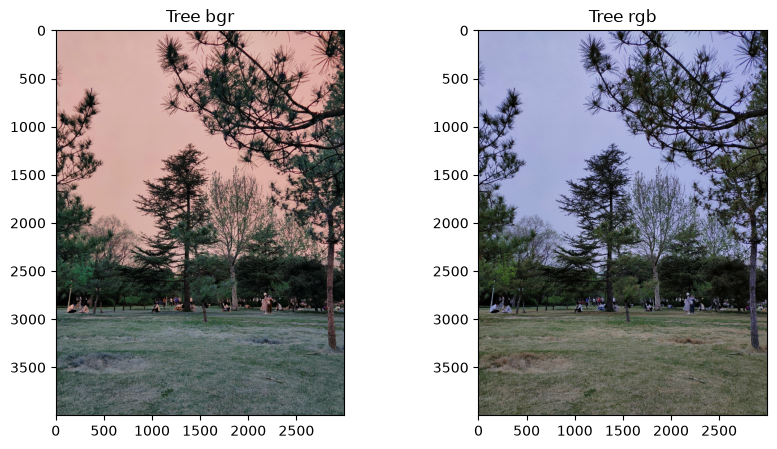

In [72]:
tree = cv.imread("tree.png")
b, g, r = cv.split(tree)
tree_rgb = cv.merge([r, g, b])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(tree)
axes[0].set_title('Tree bgr')
axes[1].imshow(tree_rgb)
axes[1].set_title('Tree rgb')
plt.show()

In [73]:
def histogram_calculate(img):
    img_h, img_w, img_c = img.shape
    histogram = np.zeros([256, img_c], np.int32)
    for x in range(img_h):
        for y in range(img_w):
            for(z) in range(img_c):
                histogram[img[x, y, z], z] += 1
    return histogram

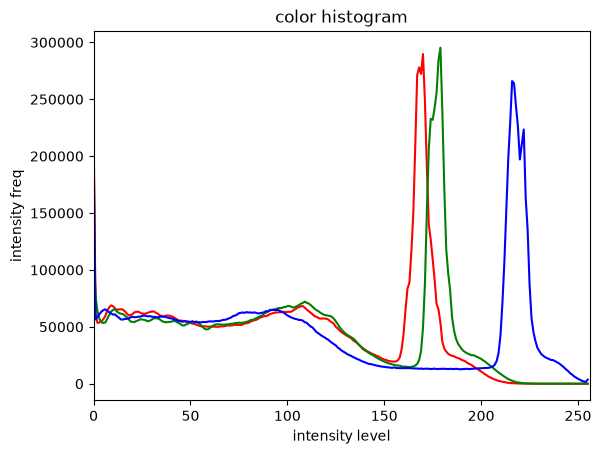

In [74]:
hist = histogram_calculate(tree_rgb)
plt.figure()
plt.title('color histogram')
plt.xlabel('intensity level')
plt.ylabel('intensity freq')
plt.xlim([0, 256])
plt.plot(hist[:, 0], 'r')
plt.plot(hist[:, 1], 'g')
plt.plot(hist[:, 2], 'b')
plt.show()

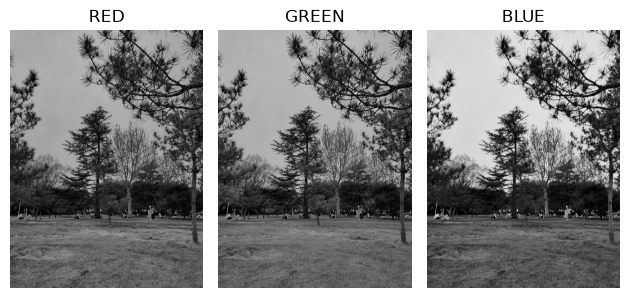

In [75]:
r, g, b = cv.split(tree_rgb)


fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3,
                                    sharex=True, sharey=True)
for aa in (ax1, ax2, ax3):
    aa.set_axis_off()

ax1.imshow(r, 'gray')
ax1.set_title('RED')
ax2.imshow(g, 'gray')
ax2.set_title('GREEN')
ax3.imshow(b, 'gray')
ax3.set_title('BLUE')

plt.tight_layout()
plt.show()

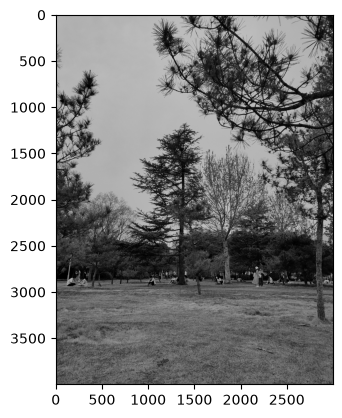

In [76]:
grayIMG = cv.cvtColor(tree, cv.COLOR_BGR2GRAY)
plt.imshow(grayIMG, cmap='gray')

In [77]:
ret, th1 = cv.threshold(grayIMG, 127, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(grayIMG, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
th3 = cv.adaptiveThreshold(grayIMG, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

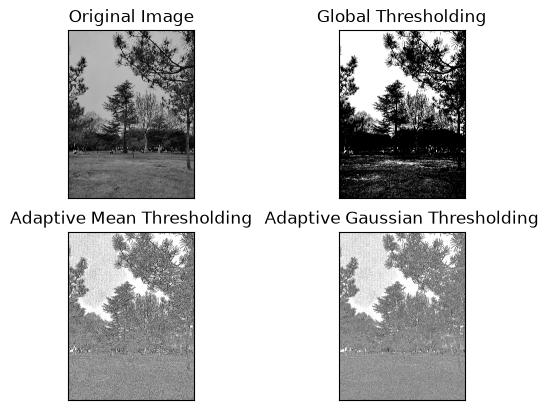

In [78]:
titles = ['Original Image', 'Global Thresholding', 'Adaptive Mean Thresholding', 'Adaptive Gaussian Thresholding']
images = [grayIMG, th1, th2, th3]
for idx in range(4):
    plt.subplot(2, 2, idx + 1)
    plt.imshow(images[idx], 'gray')
    plt.title(titles[idx])
    plt.xticks([])
    plt.yticks([])
plt.show()

In [79]:
tree = tree_rgb
print(type(tree))

<class 'numpy.ndarray'>


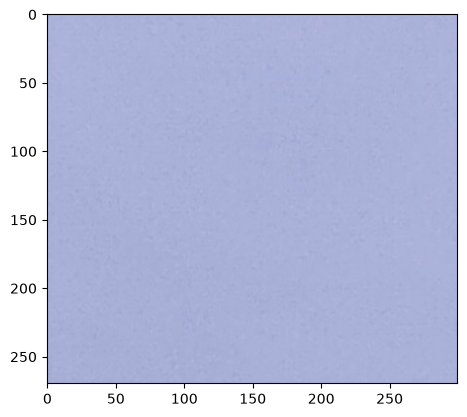

In [80]:
cropped = tree[800:1070, 550:850]
plt.imshow(cropped)

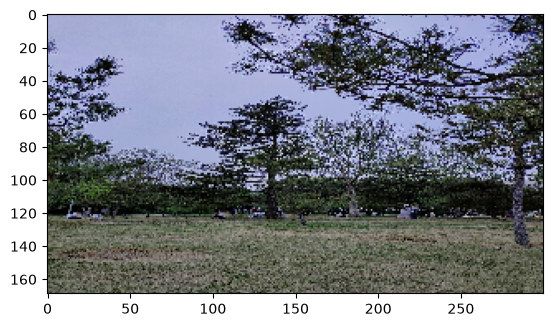

In [81]:
dim = (300, 169)
res = cv.resize(tree, dim, interpolation=cv.INTER_CUBIC)
plt.imshow(res)

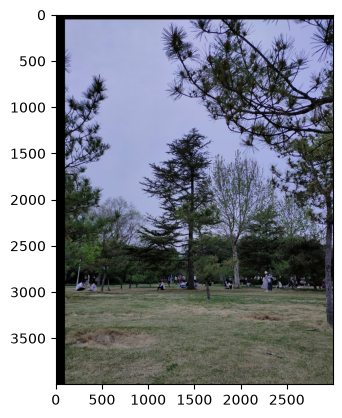

In [82]:
rows, cols = tree.shape[:2]
M = np.float32([[1, 0, 100], [0, 1, 50]])
dst = cv.warpAffine(tree, M, (cols, rows))
plt.imshow(dst)

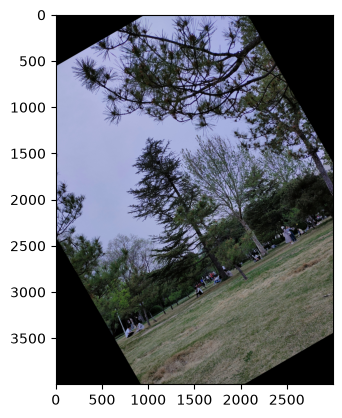

In [83]:
M = cv.getRotationMatrix2D(((cols - 1) / 2.0, (rows - 1) / 2.0), 30, 1)
dst = cv.warpAffine(tree, M, (cols, rows))
plt.imshow(dst)

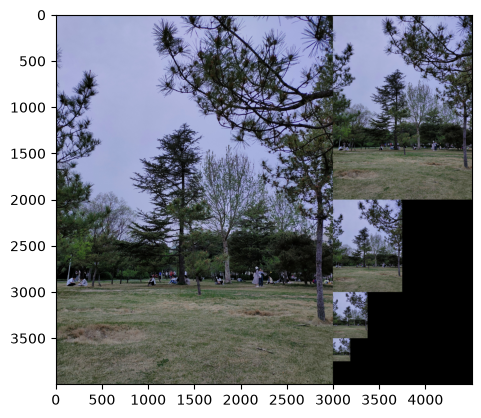

In [84]:
layer = tree.copy()

rows, cols, dim = layer.shape
composite_image = np.zeros((rows, cols + cols // 2, 3), dtype=np.uint8)
composite_image[:rows, :cols, :] = layer
i_row = 0

for i in range(4):
    layer = cv.pyrDown(layer)
    n_rows, n_cols = layer.shape[:2]
    composite_image[i_row:i_row + n_rows, cols:cols + n_cols] = layer
    i_row += n_rows

fig, ax = plt.subplots()
ax.imshow(composite_image)
plt.show()

In [85]:
img = tree.copy()
new_image = np.zeros(img.shape, img.dtype)
alpha = 1.0
beta = 40

for y in range(img.shape[0]):
    for x in range(img.shape[1]):
        for c in range(img.shape[2]):
            new_image[y, x, c] = np.clip(alpha * img[y, x, c] + beta, 0, 255)

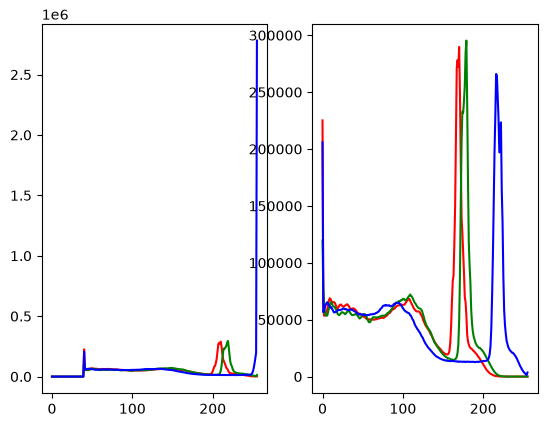

In [86]:
fig, ax = plt.subplots(1,2)
color = ('r', 'g', 'b')
for i, col in enumerate(color):
  histr = cv.calcHist([new_image], [i], None, [256], [0, 256])
  hist_orig = cv.calcHist([tree], [i], None, [256], [0, 256])
  ax[0].plot(histr, color=col)
  ax[1].plot(hist_orig, color=col)

In [87]:
lookUpTable = np.empty((1, 256), np.uint8)
gamma = 1.2
for i in range(256):
  lookUpTable[0, i] = np.clip(pow(i / 255.0, gamma) * 255.0, 0, 255)
res = cv.LUT(img, lookUpTable)

Text(0.5, 1.0, 'Gamma correction')

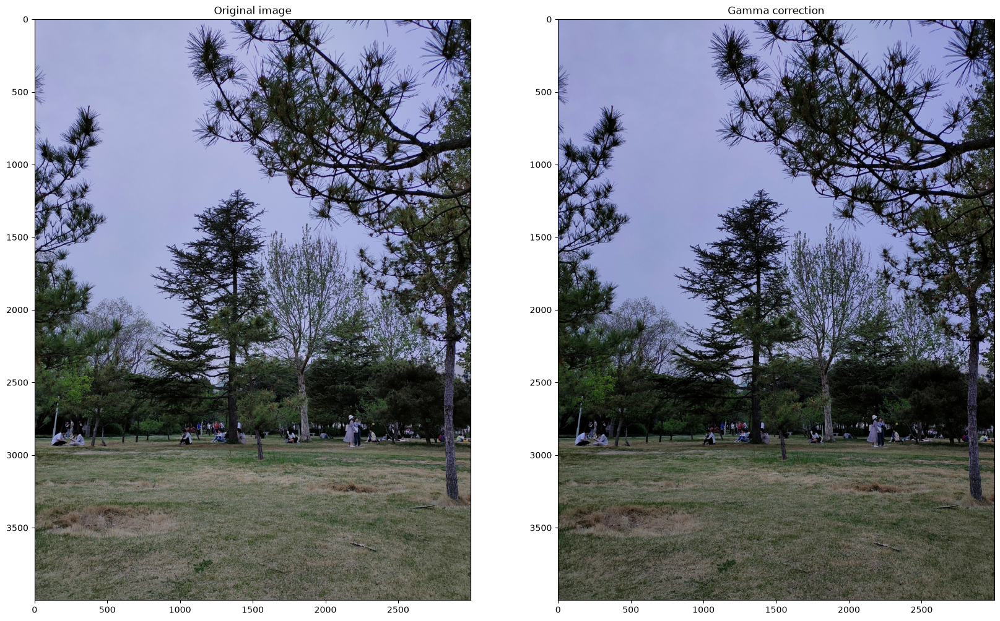

In [88]:
fig, ax = plt.subplots(1, 2, figsize=(20, 20))
ax[0].imshow(img)
ax[0].set_title('Original image')
ax[1].imshow(res)
ax[1].set_title('Gamma correction')

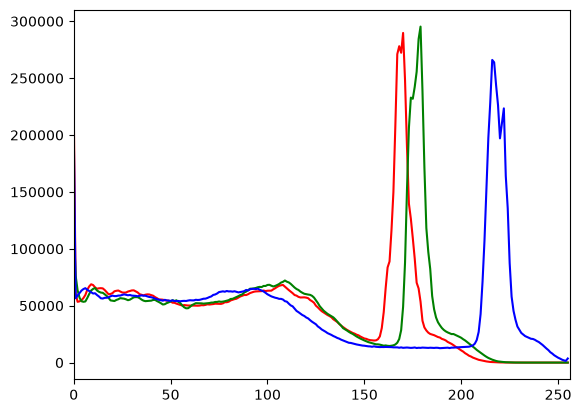

In [89]:
color = ('r', 'g', 'b')
for i, col in enumerate(color):
    histr = cv.calcHist([tree], [i], None, [256], [0, 256])
    plt.plot(histr, color=col)
    plt.xlim([0, 256])
plt.show()

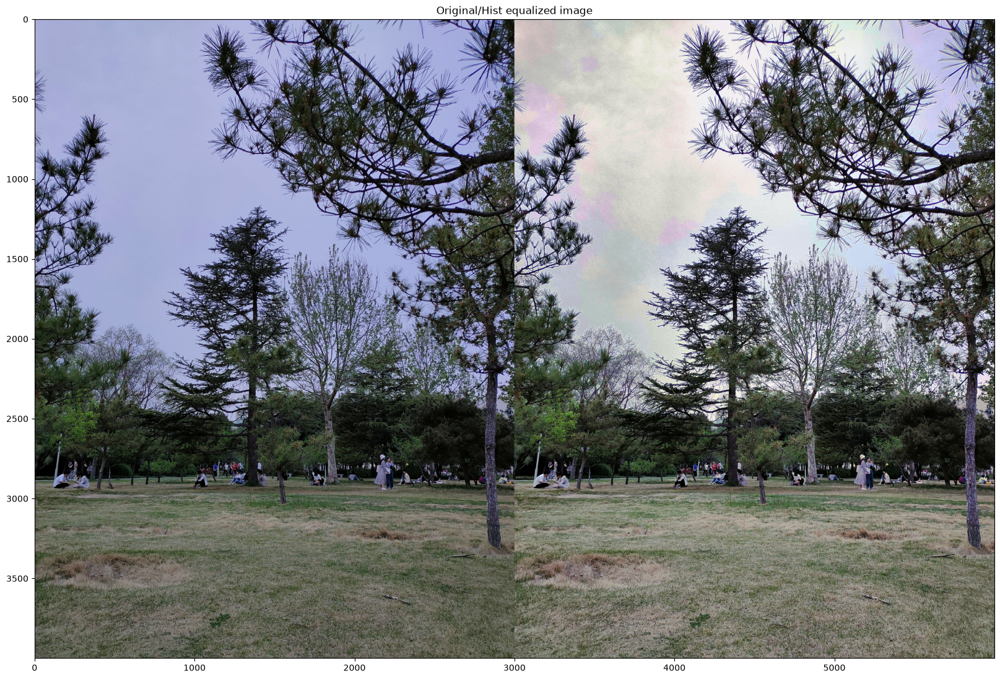

In [90]:
# Histogram equalize
d1 = cv.equalizeHist(img[:, :, 0])
d2 = cv.equalizeHist(img[:, :, 1])
d3 = cv.equalizeHist(img[:, :, 2])
equ = cv.merge([d1, d2, d3])
res = np.hstack((img, equ))
fig, ax = plt.subplots(figsize=(20, 20))
ax.imshow(res)
ax.set_title('Original/Hist equalized image')
plt.show()

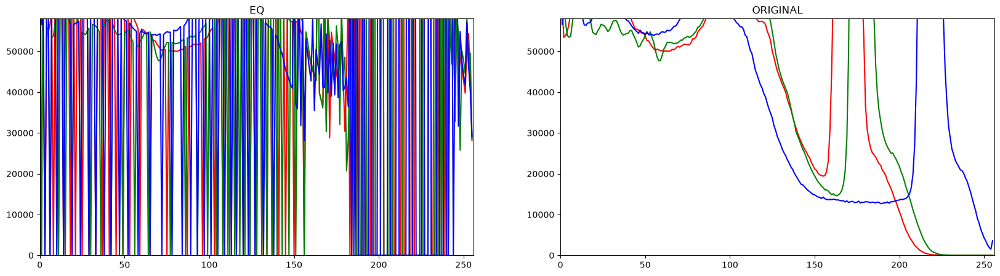

In [91]:
fig, ax = plt.subplots(1,2, figsize=(20, 5))

color = ('r', 'g', 'b')
for i, col in enumerate(color):
  histeq = cv.calcHist([equ], [i], None, [256], [0, 256])
  hist_orig = cv.calcHist([tree], [i], None, [256], [0, 256])
  ax[0].plot(histeq, color=col)
  ax[1].plot(hist_orig, color=col)

ax[0].set_title('EQ')
ax[1].set_title('ORIGINAL')

ax[0].set_xlim([0, 256])
ax[0].set_ylim([0, 58000])

ax[1].set_xlim([0, 256])
ax[1].set_ylim([0, 58000])

plt.show()

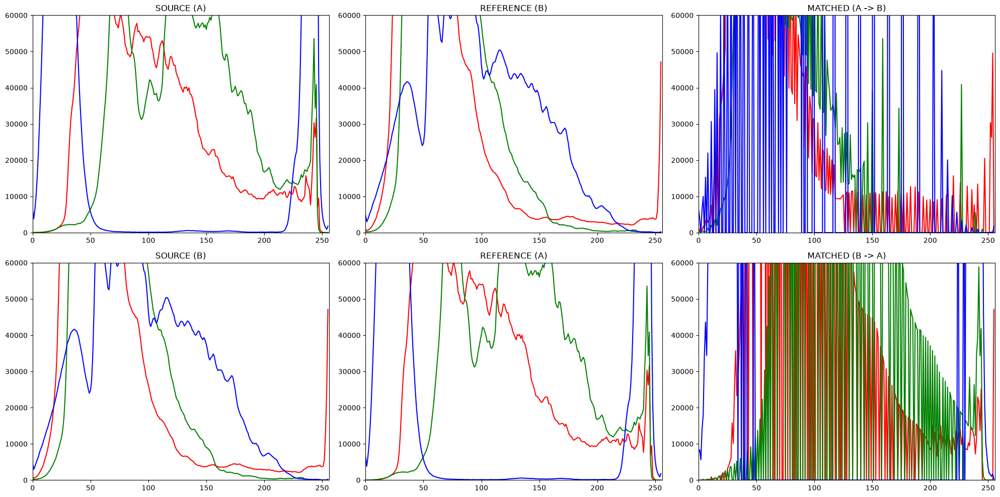

In [92]:
import cv2 as cv
import matplotlib.pyplot as plt
from skimage.exposure import match_histograms

# 1. 读取图像并转换为 RGB 格式
img_a = cv.cvtColor(cv.imread("a.jpg"), cv.COLOR_BGR2RGB)
img_b = cv.cvtColor(cv.imread("b.jpg"), cv.COLOR_BGR2RGB)

# 2. 执行双向直方图匹配
matched_a_to_b = match_histograms(img_a, img_b, channel_axis=2)
matched_b_to_a = match_histograms(img_b, img_a, channel_axis=2)

# 3. 创建 2行3列 的画布来展示双向直方图对比
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
color = ('r', 'g', 'b')

# ==================== 第一行：A -> B ====================
for i, col in enumerate(color):
    histsrc = cv.calcHist([img_a], [i], None, [256], [0, 256])
    hist_ref = cv.calcHist([img_b], [i], None, [256], [0, 256])
    histmat = cv.calcHist([matched_a_to_b], [i], None, [256], [0, 256])

    axes[0, 0].plot(histsrc, color=col)
    axes[0, 1].plot(hist_ref, color=col)
    axes[0, 2].plot(histmat, color=col)

axes[0, 0].set_title('SOURCE (A)')
axes[0, 1].set_title('REFERENCE (B)')
axes[0, 2].set_title('MATCHED (A -> B)')


# ==================== 第二行：B -> A ====================
for i, col in enumerate(color):
    histsrc_b = cv.calcHist([img_b], [i], None, [256], [0, 256])
    hist_ref_a = cv.calcHist([img_a], [i], None, [256], [0, 256])
    histmat_b = cv.calcHist([matched_b_to_a], [i], None, [256], [0, 256])

    axes[1, 0].plot(histsrc_b, color=col)
    axes[1, 1].plot(hist_ref_a, color=col)
    axes[1, 2].plot(histmat_b, color=col)

axes[1, 0].set_title('SOURCE (B)')
axes[1, 1].set_title('REFERENCE (A)')
axes[1, 2].set_title('MATCHED (B -> A)')


# 4. 统一设置所有子图的坐标轴范围与布局
for row in axes:
    for ax in row:
        ax.set_xlim([0, 256])
        ax.set_ylim([0, 60000])

plt.tight_layout()
plt.show()

## solution1


In [93]:
import numpy as np

In [111]:
image = np.array([
    [10, 10, 10,  0,  0],
    [10, 10, 10,  0,  0],
    [10, 10, 10,  0,  0],
    [10, 10, 10,  0,  0],
    [10, 10, 10,  0,  0]
], dtype=np.float32)
kernel = 1/9 * np.ones([3, 3])
kernel_ = 1/16 * np.array([[1,2,1], [2,4,2], [1,2,1]])
image, kernel, kernel_

(array([[10., 10., 10.,  0.,  0.],
        [10., 10., 10.,  0.,  0.],
        [10., 10., 10.,  0.,  0.],
        [10., 10., 10.,  0.,  0.],
        [10., 10., 10.,  0.,  0.]], dtype=float32),
 array([[0.11111111, 0.11111111, 0.11111111],
        [0.11111111, 0.11111111, 0.11111111],
        [0.11111111, 0.11111111, 0.11111111]]),
 array([[0.0625, 0.125 , 0.0625],
        [0.125 , 0.25  , 0.125 ],
        [0.0625, 0.125 , 0.0625]]))

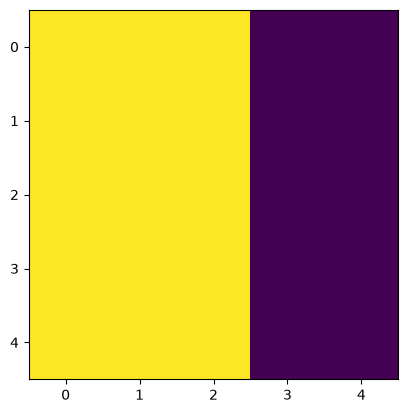

In [103]:
plt.imshow(image)

In [104]:
kernel_flipped = np.flip(np.flip(kernel, axis=0), axis=1)
padded_img = np.pad(image, pad_width=((1,1), (1,1)), mode='constant', constant_values=0)
window = padded_img[1: 1+3, 1:1+3]
pixel_val = np.sum(window * kernel_flipped)
h, w = image.shape
output = np.zeros_like(image)
for i in range(h):
  for j in range(w):
    cur_win = padded_img[i:i+3, j:j+3]
    output[i, j] = np.sum(cur_win * kernel_flipped)
output


array([[3.3333333, 5.       , 3.3333333, 1.6666666, 0.       ],
       [5.       , 7.5      , 5.       , 2.5      , 0.       ],
       [5.       , 7.5      , 5.       , 2.5      , 0.       ],
       [5.       , 7.5      , 5.       , 2.5      , 0.       ],
       [3.3333333, 5.       , 3.3333333, 1.6666666, 0.       ]],
      dtype=float32)

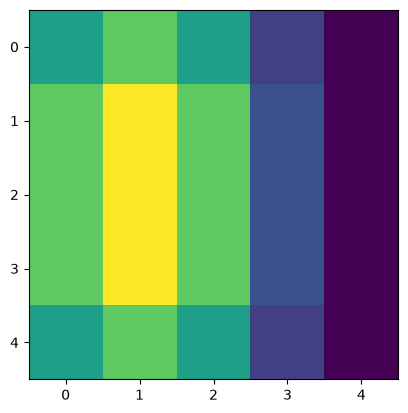

In [105]:
kernel_flipped_ = np.flip(np.flip(kernel_, axis=0), axis=1)
padded_img_ = np.pad(image, pad_width=((1,1), (1,1)), mode='constant', constant_values=0)
window_ = padded_img_[1: 1+3, 1:1+3]
pixel_val_ = np.sum(window_ * kernel_flipped_)
h_, w_ = image.shape
output_ = np.zeros_like(image)
for i in range(h_):
  for j in range(w_):
    cur_win_ = padded_img_[i:i+3, j:j+3]
    output_[i, j] = np.sum(cur_win_ * kernel_flipped_)
output_
plt.imshow(output_)

In [106]:
def convolve2d(image: np.ndarray, kernel: np.ndarray):
  if kernel.ndim != 2:
    raise ValueError("dim of kernel must be 2d.")
  kh, kw = kernel.shape
  pad_h, pad_w = kh // 2, kw // 2
  kernel_flipped = np.flip(np.flip(kernel, axis=0), axis=1)
  if image.ndim == 2:
    h, w = image.shape
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(h):
      for j in range(w):
        window = padded[i:i+kh, j:j+kw]
        output[i, j] = np.sum(window * kernel_flipped)
    return output
  elif image.ndim == 3:
    h, w, c = image.shape
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w), (0, 0)), mode='constant', constant_values=0)
    output = np.zeros_like(image, dtype=np.float32)
    for ch in range(c):
      for i in range(h):
        for j in range(w):
          window = padded[i:i+kh, j:j+kw, ch]
          output[i, j ,ch] = np.sum(window * kernel_flipped)
    return output

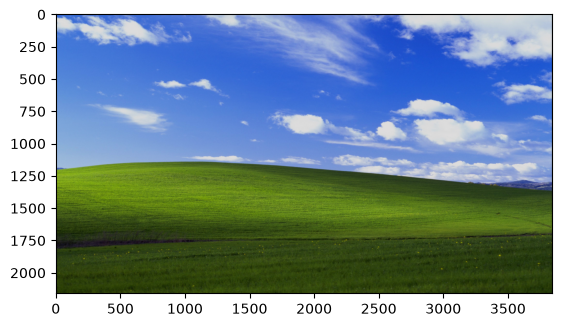

In [114]:
a = cv.imread("a.jpg")
b, g, r = cv.split(a)
a_rgb = cv.merge([r, g, b])
a_avg = convolve2d(a_rgb, 0.9 * kernel_)
plt.imshow(a_avg.astype(np.uint8), vmin=0, vmax=255)

Text(0.5, 1.0, 'gau')

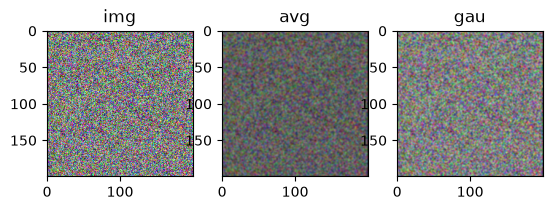

In [108]:
rand_img = np.random.uniform(0, 255, size=(200, 200, 3))
avg = convolve2d(rand_img, kernel)
gau = convolve2d(rand_img, kernel_)
fig, ax = plt.subplots(1, 3)
ax[0].imshow(rand_img.astype(np.uint8), vmin=0, vmax=255)
ax[0].set_title('img')
ax[1].imshow(avg.astype(np.uint8), vmin=0, vmax=255)
ax[1].set_title('avg')
ax[2].imshow(gau.astype(np.uint8), vmin=0, vmax=255)
ax[2].set_title('gau')

In [109]:
uw = cv.imread("uw.jpeg")
b, g, r = cv.split(uw)
uw = cv.merge([r, g, b])
avg_ = convolve2d(uw, kernel)
gau_ = convolve2d(uw, kernel_)
fig, ax = plt.subplots(1, 3, figsize=(200,200))
ax[0].imshow(uw.astype(np.uint8), vmin=0, vmax=255)
ax[0].set_title('img')
ax[1].imshow(avg_.astype(np.uint8), vmin=0, vmax=255)
ax[1].set_title('avg')
ax[2].imshow(gau_.astype(np.uint8), vmin=0, vmax=255)
ax[2].set_title('gau')

Text(0.5, 1.0, 'gau')